# Thompson Sampling

# Thompson Sampling Algorithm

## Step 1

At each round $n$, we consider two numbers for each ad $i$:

- $N_i^1(n)$: the number of times ad $i$ received reward $1$ up to round $n$.
- $N_i^0(n)$: the number of times ad $i$ received reward $0$ up to round $n$.

## Step 2

For each ad $i$, we take a random draw from the distribution:

$$
\theta_i(n) = \beta\left(N_i^1(n) + 1,\; N_i^0(n) + 1\right)
$$

## Step 3

We select the ad with the highest $\theta_i(n)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Importing the dataset

In [2]:
dataset = pd.read_csv('../data/Ads_CTR_Optimisation.csv')

## Implementing Thompson Sampling

In [3]:
import random

# total number of rounds (users / rows in the dataset)
N = dataset.shape[0]
# total number of ads (columns in the dataset)
d = dataset.shape[1]
# full list of the ads selected in each round (one entry per row) - this will be used to visualise the results
ads_selected = []
# step 1
# number of times the ad i received reward 1 up to round n (N_i^1(n)) (starting with a list of zeros for each ad)
numbers_of_rewards_1 = [0] * d
# number of times the ad i received reward 0 up to round n (N_i^0(n)) (starting with a list of zeros for each ad)
numbers_of_rewards_0 = [0] * d
total_reward = 0

for n in range(0, N):
    ad = 0
    max_random = 0
    for i in range(0, d):
        # step 2: take a random draw from the distribution for ad i
        random_beta = random.betavariate(numbers_of_rewards_1[i] + 1, numbers_of_rewards_0[i] + 1)
        # step 3: select the ad with the highest theta_i(n)
        if random_beta > max_random:
            max_random = random_beta
            ad = i
    ads_selected.append(ad)
    reward = dataset.values[n, ad]
    if reward == 1:
        numbers_of_rewards_1[ad] = numbers_of_rewards_1[ad] + 1
    else:
        numbers_of_rewards_0[ad] = numbers_of_rewards_0[ad] + 1
    total_reward = total_reward + reward

## Visualising the results - Histogram

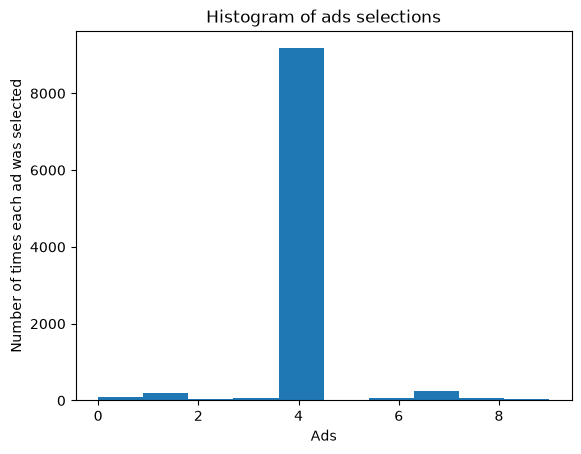

In [4]:
plt.hist(ads_selected)
plt.title('Histogram of ads selections')
plt.xlabel('Ads')
plt.ylabel('Number of times each ad was selected')
plt.show()